In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('lab2_2_DS.csv')
df.head()

,Temperature (°C),Ice Cream Sales (units)
0,-4.662263,41.842986
1,-4.316559,34.661120
2,-4.213985,39.383001
3,-3.949661,37.539845
4,-3.578554,32.284531


In [3]:
x = df[['Temperature (°C)']]
y = df['Ice Cream Sales (units)']

Делим данные

In [4]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

Создание полиномиальной регрессии

In [5]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

# Создаём словарь моделей
models = {}

# Линейная регрессия
models['Linear'] = LinearRegression

# Полиномиальные модели
for degree in [2, 3, 4, 5]:
    models[f'Polynomial {degree}'] = degree

Обучение модели

In [6]:
poly_models = {}

for name, degree in models.items():
    if name == 'Linear':
        model = LinearRegression()
        model.fit(x_train, y_train)
    else:
        poly = PolynomialFeatures(degree=degree)

        x_train_poly = poly.fit_transform(x_train)

        model = LinearRegression()
        model.fit(x_train_poly, y_train)

        poly_models[name] = poly
    if name == 'Linear':
        poly_models[name] = None
    models[name] = model


Построение графика

c:\Users\alena\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
c:\Users\alena\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(
c:\Users\alena\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(
c:\Users\alena\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(
c:\Users\alena\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validat

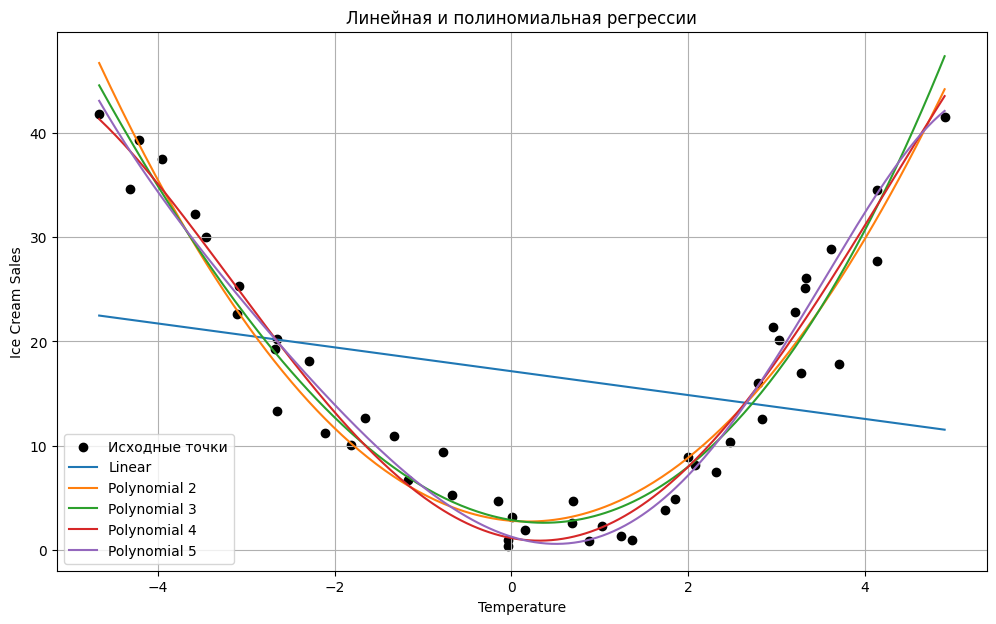

In [7]:
plt.figure(figsize=(12, 7))

plt.scatter(x, y, color='black', label='Исходные точки')

x_plot = np.linspace(x.min().iloc[0], x.max().iloc[0], 300).reshape(-1, 1)

# Регрессионные кривые
for name, model in models.items():
    if name == 'Linear':
        y_plot = model.predict(x_plot)
    else:
        x_plot_poly = poly_models[name].transform(x_plot)
        y_plot = model.predict(x_plot_poly)
    plt.plot(x_plot, y_plot, label=name)

plt.xlabel('Temperature')
plt.ylabel('Ice Cream Sales')
plt.title('Линейная и полиномиальная регрессии')
plt.legend()
plt.grid()
plt.show()

Метрики

In [ ]:
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_percentage_error

results = {}

for name, model in models.items():
    if name == 'Linear':
        y_pred = model.predict(x_test)

    else:
        x_test_poly = poly_models[name].transform(x_test)
        y_pred = model.predict(x_test_poly)

    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    mape = mean_absolute_percentage_error(y_test, y_pred) * 100

    results[name] = [mse, r2, mape]

    print(f'\n{name}')
    print(f'MSE: {mse:.2f}')
    print(f'R2: {r2:.4f}')
    print(f'MAPE: {mape:.2f}%')


Linear
MSE: 149.33
R2: -0.5751
MAPE: 358.74%

Polynomial 2
MSE: 14.88
R2: 0.8431
MAPE: 68.72%

Polynomial 3
MSE: 15.12
R2: 0.8405
MAPE: 59.60%

Polynomial 4
MSE: 18.44
R2: 0.8054
MAPE: 45.74%

Polynomial 5
MSE: 21.03
R2: 0.7782
MAPE: 39.57%


In [ ]:
results_df = pd.DataFrame(results,
    index=['MSE', 'R2', 'MAPE (%)']).T

print(results_df.round(4))

                   MSE      R2  MAPE (%)
Linear        149.3263 -0.5751  358.7373
Polynomial 2   14.8788  0.8431   68.7247
Polynomial 3   15.1200  0.8405   59.5957
Polynomial 4   18.4442  0.8054   45.7386
Polynomial 5   21.0308  0.7782   39.5699


In [10]:
print('Лучшая модель по MSE:', results_df['MSE'].idxmin())
print('Лучшая модель по R2:', results_df['R2'].idxmax())
print('Лучшая модель по MAPE:', results_df['MAPE (%)'].idxmin())

Лучшая модель по MSE: Polynomial 2
Лучшая модель по R2: Polynomial 2
Лучшая модель по MAPE: Polynomial 5


ВЫВОДЫ
Линейная регрессия показала самый худший результат для данного датасета.
По результатам метрик MSE и R2 наилучшие результаты показала полиномиальная регрессия второй степени, по MAPE - пятой степени.